# Notebook 2 — Pemodelan & Evaluasi
**Kasus 08 Prediksi Keterlambatan Paket**

In [1]:
import sys
sys.path.insert(0, "..")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    classification_report, confusion_matrix, PrecisionRecallDisplay,
)

from src.features import (
    add_derived_features, COLS_NUMERIK, COLS_TURUNAN, COLS_KATEGORI, FITUR_INPUT,
)

sns.set_theme(style="whitegrid", palette="muted")
warnings.filterwarnings("ignore", category=FutureWarning)

CLEAN_PATH = "../data/clean.csv"
MODEL_PATH = "../artifacts/model.joblib"
META_PATH = "../artifacts/metadata.json"

# Biaya bisnis
BIAYA_FN = 50_000  # Rp — terlambat tanpa kabar
BIAYA_FP = 5_000   # Rp — salah alarm

## 1 · Muat & Bagi Data berdasarkan Waktu

In [2]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["tanggal_pickup"])
print(f"Total baris bersih: {len(df):,}")

# Pembagian waktu sesuai brief.md
mask_train = df["tanggal_pickup"] < "2026-01-01"
mask_val   = (df["tanggal_pickup"] >= "2026-01-01") & (df["tanggal_pickup"] < "2026-04-01")
mask_test  = df["tanggal_pickup"] >= "2026-04-01"

df_train = df[mask_train].copy()
df_val   = df[mask_val].copy()
df_test  = df[mask_test].copy()

print(f"\nTrain     : {len(df_train):>6,} baris  ({df_train['terlambat'].mean():.1%} positif)")
print(f"Validation: {len(df_val):>6,} baris  ({df_val['terlambat'].mean():.1%} positif)")
print(f"Test      : {len(df_test):>6,} baris  ({df_test['terlambat'].mean():.1%} positif)")

Total baris bersih: 40,000

Train     : 26,633 baris  (17.8% positif)
Validation:  6,623 baris  (21.9% positif)
Test      :  6,744 baris  (13.9% positif)


## 2 · Feature Engineering

In [3]:
# Hitung volume_q75 hanya dari data train (mencegah data leakage)
volume_q75_train = df_train["volume_hub_hari"].quantile(0.75)
print(f"Persentil 75 volume_hub_hari (Train): {volume_q75_train:.0f}")

# Tambahkan fitur turunan menggunakan statistik dari train
df_train = add_derived_features(df_train, volume_q75=volume_q75_train)
df_val   = add_derived_features(df_val,   volume_q75=volume_q75_train)
df_test  = add_derived_features(df_test,  volume_q75=volume_q75_train)

print(f"Fitur turunan berhasil ditambahkan.")
print(f"Total fitur input: {len(FITUR_INPUT)}")
print(f"Fitur: {FITUR_INPUT}")

Persentil 75 volume_hub_hari (Train): 5907
Fitur turunan berhasil ditambahkan.
Total fitur input: 18
Fitur: ['jam_pickup', 'jarak_km', 'jumlah_transit', 'janji_hari', 'berat_kg', 'volume_hub_hari', 'pickup_sore', 'bulan', 'hari_minggu', 'bulan_puncak', 'hari_senin', 'rasio_jarak_janji', 'transit_per_janji', 'volume_tinggi', 'layanan', 'kota_tujuan', 'metode_bayar', 'cuaca_saat_pickup']


In [4]:
# Pisahkan X dan y
TARGET = "terlambat"

X_train = df_train[FITUR_INPUT]
y_train = df_train[TARGET]

X_val = df_val[FITUR_INPUT]
y_val = df_val[TARGET]

X_test = df_test[FITUR_INPUT]
y_test = df_test[TARGET]

print(f"X_train: {X_train.shape}")
print(f"X_val  : {X_val.shape}")
print(f"X_test : {X_test.shape}")

X_train: (26633, 18)
X_val  : (6623, 18)
X_test : (6744, 18)


## 3 · Pipeline Prapemrosesan

Pipeline ini memastikan:
- Imputasi numerik menggunakan **median dari data train** saja.
- Scaling hanya di-fit pada data train.
- Encoding kategorikal konsisten.
- Tidak ada data leakage.

In [5]:
# Kolom numerik = COLS_NUMERIK + COLS_TURUNAN (semua numerik)
fitur_num = COLS_NUMERIK + COLS_TURUNAN
fitur_cat = COLS_KATEGORI

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), fitur_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="tidak_diketahui")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), fitur_cat),
    ],
    remainder="drop",
)

print("Preprocessor siap.")
print(f"Fitur numerik ({len(fitur_num)}): {fitur_num}")
print(f"Fitur kategorikal ({len(fitur_cat)}): {fitur_cat}")

Preprocessor siap.
Fitur numerik (14): ['jam_pickup', 'jarak_km', 'jumlah_transit', 'janji_hari', 'berat_kg', 'volume_hub_hari', 'pickup_sore', 'bulan', 'hari_minggu', 'bulan_puncak', 'hari_senin', 'rasio_jarak_janji', 'transit_per_janji', 'volume_tinggi']
Fitur kategorikal (4): ['layanan', 'kota_tujuan', 'metode_bayar', 'cuaca_saat_pickup']


## 4 · Model Baseline — Logistic Regression

In [6]:
pipe_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    )),
])

pipe_lr.fit(X_train, y_train)

# Probabilitas pada validation
y_val_proba_lr = pipe_lr.predict_proba(X_val)[:, 1]
prauc_lr_val = average_precision_score(y_val, y_val_proba_lr)

print(f"Baseline Logistic Regression")
print(f"PR-AUC (Validation): {prauc_lr_val:.4f}")

Baseline Logistic Regression
PR-AUC (Validation): 0.6587


## 5 · Model Kandidat — HistGradientBoosting

In [7]:
# HistGradientBoostingClassifier mendukung NaN secara native,
# tetapi kita tetap pakai pipeline yang sama untuk konsistensi encoding.

pipe_hgb = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_depth=6,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
    )),
])

pipe_hgb.fit(X_train, y_train)

y_val_proba_hgb = pipe_hgb.predict_proba(X_val)[:, 1]
prauc_hgb_val = average_precision_score(y_val, y_val_proba_hgb)

print(f"HistGradientBoosting")
print(f"PR-AUC (Validation): {prauc_hgb_val:.4f}")

HistGradientBoosting
PR-AUC (Validation): 0.6531


## 6 · Perbandingan Model

In [8]:
print("=" * 50)
print("PERBANDINGAN PR-AUC (VALIDATION)")
print("=" * 50)
print(f"Baseline (Logistic Regression) : {prauc_lr_val:.4f}")
print(f"Kandidat (HistGradientBoosting): {prauc_hgb_val:.4f}")

if prauc_hgb_val > prauc_lr_val:
    print(f"\n→ HistGradientBoosting unggul (+{prauc_hgb_val - prauc_lr_val:.4f})")
    model_terbaik = pipe_hgb
    nama_model = "HistGradientBoostingClassifier"
    y_val_proba = y_val_proba_hgb
    prauc_val = prauc_hgb_val
else:
    print(f"\n→ Logistic Regression setara/lebih baik")
    model_terbaik = pipe_lr
    nama_model = "LogisticRegression"
    y_val_proba = y_val_proba_lr
    prauc_val = prauc_lr_val

print(f"\nModel terpilih: {nama_model}")

PERBANDINGAN PR-AUC (VALIDATION)
Baseline (Logistic Regression) : 0.6587
Kandidat (HistGradientBoosting): 0.6531

→ Logistic Regression setara/lebih baik

Model terpilih: LogisticRegression


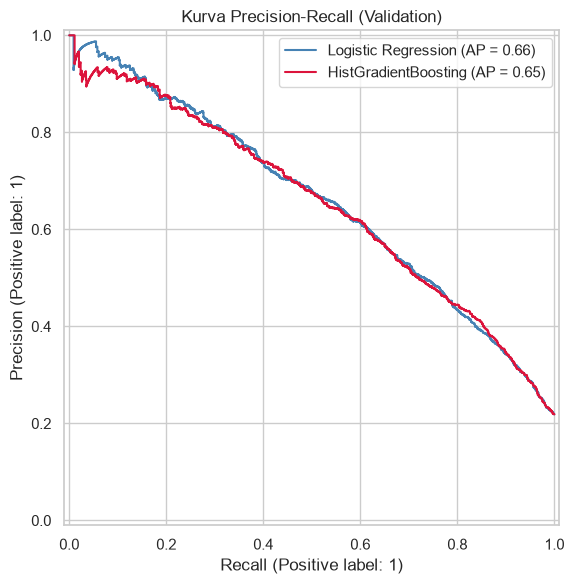

In [9]:
# Kurva PR kedua model
fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_val, y_val_proba_lr, name="Logistic Regression", ax=ax, color="steelblue"
)
PrecisionRecallDisplay.from_predictions(
    y_val, y_val_proba_hgb, name="HistGradientBoosting", ax=ax, color="crimson"
)

ax.set_title("Kurva Precision-Recall (Validation)")
ax.legend()
plt.tight_layout()
plt.savefig("../artifacts/kurva_pr_validation.png", dpi=150, bbox_inches="tight")
plt.show()

## 7 · Penentuan Threshold Optimal (Biaya Bisnis)

**Aturan biaya:**
- False Negative (terlambat tanpa kabar) = Rp 50.000
- False Positive (salah alarm) = Rp 5.000

Threshold optimal meminimalkan total biaya pada data Validation.

In [10]:
precision_arr, recall_arr, thresholds_arr = precision_recall_curve(y_val, y_val_proba)

# Hitung total biaya untuk setiap threshold
biaya_total = []
n_val = len(y_val)
n_positif = y_val.sum()
n_negatif = n_val - n_positif

for t in thresholds_arr:
    y_pred_t = (y_val_proba >= t).astype(int)
    fn = ((y_val == 1) & (y_pred_t == 0)).sum()
    fp = ((y_val == 0) & (y_pred_t == 1)).sum()
    total = fn * BIAYA_FN + fp * BIAYA_FP
    biaya_total.append(total)

biaya_total = np.array(biaya_total)
idx_optimal = np.argmin(biaya_total)
threshold_optimal = thresholds_arr[idx_optimal]

print(f"Threshold optimal: {threshold_optimal:.4f}")
print(f"Biaya minimum pada validation: Rp {biaya_total[idx_optimal]:,.0f}")

Threshold optimal: 0.3446
Biaya minimum pada validation: Rp 19,580,000


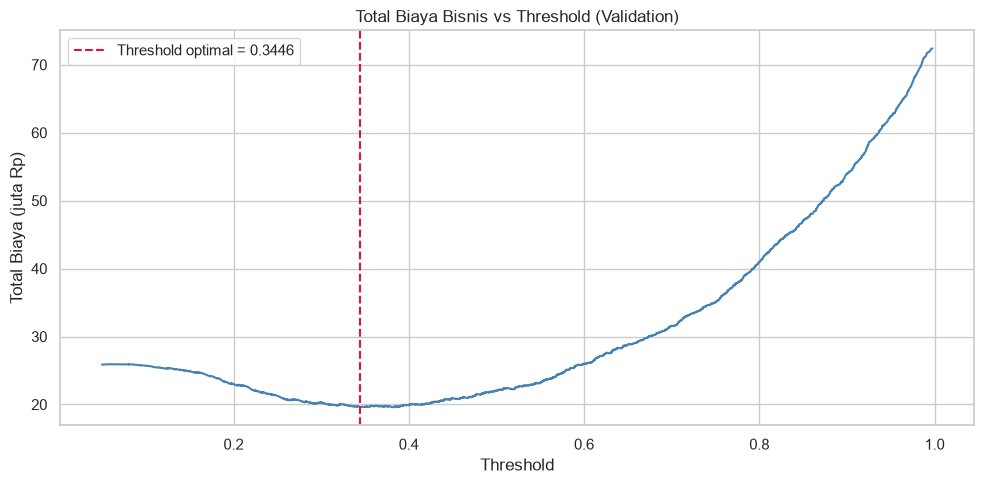

In [11]:
# Visualisasi biaya vs threshold
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds_arr, biaya_total / 1_000_000, color="steelblue", linewidth=1.5)
ax.axvline(threshold_optimal, color="crimson", linestyle="--",
           label=f"Threshold optimal = {threshold_optimal:.4f}")
ax.set_xlabel("Threshold")
ax.set_ylabel("Total Biaya (juta Rp)")
ax.set_title("Total Biaya Bisnis vs Threshold (Validation)")
ax.legend()
plt.tight_layout()
plt.savefig("../artifacts/grafik_biaya_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Evaluasi pada validation dengan threshold optimal
y_val_pred = (y_val_proba >= threshold_optimal).astype(int)

print(f"\nClassification Report (Validation, threshold={threshold_optimal:.4f}):")
print(classification_report(y_val, y_val_pred, target_names=["Tepat waktu", "Terlambat"]))

print("Confusion Matrix (Validation):")
cm_val = confusion_matrix(y_val, y_val_pred)
print(cm_val)


Classification Report (Validation, threshold=0.3446):
              precision    recall  f1-score   support

 Tepat waktu       0.95      0.50      0.66      5174
   Terlambat       0.34      0.91      0.49      1449

    accuracy                           0.59      6623
   macro avg       0.64      0.70      0.57      6623
weighted avg       0.82      0.59      0.62      6623

Confusion Matrix (Validation):
[[2588 2586]
 [ 133 1316]]


## 8 · Evaluasi Final pada Data Test (Satu Kali)

In [13]:
y_test_proba = model_terbaik.predict_proba(X_test)[:, 1]
prauc_test = average_precision_score(y_test, y_test_proba)

y_test_pred = (y_test_proba >= threshold_optimal).astype(int)

# Biaya pada test
fn_test = ((y_test == 1) & (y_test_pred == 0)).sum()
fp_test = ((y_test == 0) & (y_test_pred == 1)).sum()
biaya_test = fn_test * BIAYA_FN + fp_test * BIAYA_FP

print("=" * 50)
print("EVALUASI FINAL — DATA TEST")
print("=" * 50)
print(f"PR-AUC (Test): {prauc_test:.4f}")
print(f"Total Biaya (Test): Rp {biaya_test:,.0f}")
print()
print(f"Classification Report (Test, threshold={threshold_optimal:.4f}):")
print(classification_report(y_test, y_test_pred, target_names=["Tepat waktu", "Terlambat"]))

cm_test = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix (Test):")
print(cm_test)

EVALUASI FINAL — DATA TEST
PR-AUC (Test): 0.3737
Total Biaya (Test): Rp 21,945,000

Classification Report (Test, threshold=0.3446):
              precision    recall  f1-score   support

 Tepat waktu       0.95      0.56      0.70      5805
   Terlambat       0.23      0.80      0.36       939

    accuracy                           0.59      6744
   macro avg       0.59      0.68      0.53      6744
weighted avg       0.85      0.59      0.66      6744

Confusion Matrix (Test):
[[3256 2549]
 [ 184  755]]


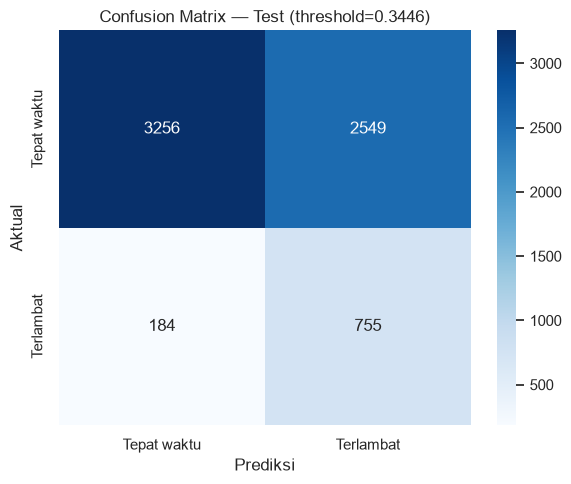

In [14]:
# Visualisasi confusion matrix Test
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Tepat waktu", "Terlambat"],
            yticklabels=["Tepat waktu", "Terlambat"], ax=ax)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_title(f"Confusion Matrix — Test (threshold={threshold_optimal:.4f})")
plt.tight_layout()
plt.savefig("../artifacts/confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 9 · Feature Importance

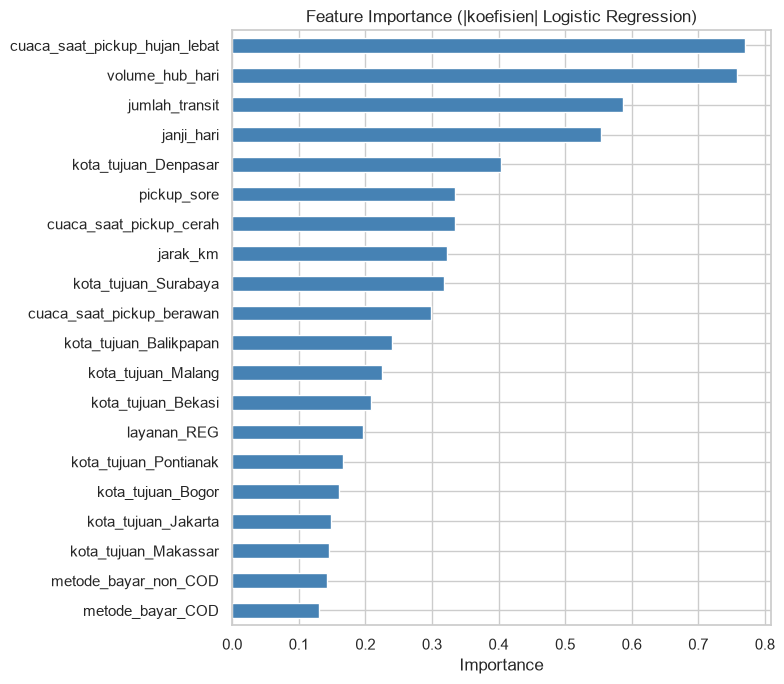


Top-10 fitur terpenting:
cuaca_saat_pickup_hujan_lebat    0.770123
volume_hub_hari                  0.758173
jumlah_transit                   0.587565
janji_hari                       0.553847
kota_tujuan_Denpasar             0.404353
pickup_sore                      0.334901
cuaca_saat_pickup_cerah          0.334653
jarak_km                         0.322541
kota_tujuan_Surabaya             0.318392
cuaca_saat_pickup_berawan        0.298325


In [15]:
# Ambil nama fitur dari preprocessor
ohe = model_terbaik.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
nama_fitur_cat = list(ohe.get_feature_names_out(fitur_cat))
nama_fitur_all = fitur_num + nama_fitur_cat

clf = model_terbaik.named_steps["classifier"]

if hasattr(clf, "feature_importances_"):
    importances = clf.feature_importances_
    judul_fi = "Feature Importance (HistGradientBoosting)"
elif hasattr(clf, "coef_"):
    importances = np.abs(clf.coef_[0])
    judul_fi = "Feature Importance (|koefisien| Logistic Regression)"
else:
    importances = None

if importances is not None:
    fi = pd.Series(importances, index=nama_fitur_all).sort_values(ascending=True)
    top_n = min(20, len(fi))

    fig, ax = plt.subplots(figsize=(8, max(6, top_n * 0.35)))
    fi.tail(top_n).plot.barh(ax=ax, color="steelblue")
    ax.set_title(judul_fi)
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig("../artifacts/feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nTop-10 fitur terpenting:")
    print(fi.tail(10).iloc[::-1].to_string())

## 10 · Simpan Artefak

In [16]:
# Simpan model
joblib.dump(model_terbaik, MODEL_PATH)
print(f"Model disimpan ke {MODEL_PATH}")

# Metadata
metadata = {
    "model": nama_model,
    "versi": "1.0.0",
    "fitur_input": FITUR_INPUT,
    "fitur_numerik": fitur_num,
    "fitur_kategorikal": fitur_cat,
    "threshold": round(float(threshold_optimal), 4),
    "volume_q75_train": round(float(volume_q75_train), 2),
    "biaya_fn": BIAYA_FN,
    "biaya_fp": BIAYA_FP,
    "metrik_validation": {
        "pr_auc": round(float(prauc_val), 4),
        "biaya_total_rp": int(biaya_total[idx_optimal]),
    },
    "metrik_test": {
        "pr_auc": round(float(prauc_test), 4),
        "biaya_total_rp": int(biaya_test),
    },
    "metrik_baseline": {
        "model": "LogisticRegression",
        "pr_auc_validation": round(float(prauc_lr_val), 4),
    },
    "pembagian_data": {
        "train": "< 2026-01-01",
        "validation": "2026-01-01 s.d. 2026-03-31",
        "test": ">= 2026-04-01",
    },
}

with open(META_PATH, "w") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"Metadata disimpan ke {META_PATH}")
print("\nIsi metadata:")
print(json.dumps(metadata, indent=2, ensure_ascii=False))

Model disimpan ke ../artifacts/model.joblib
Metadata disimpan ke ../artifacts/metadata.json

Isi metadata:
{
  "model": "LogisticRegression",
  "versi": "1.0.0",
  "fitur_input": [
    "jam_pickup",
    "jarak_km",
    "jumlah_transit",
    "janji_hari",
    "berat_kg",
    "volume_hub_hari",
    "pickup_sore",
    "bulan",
    "hari_minggu",
    "bulan_puncak",
    "hari_senin",
    "rasio_jarak_janji",
    "transit_per_janji",
    "volume_tinggi",
    "layanan",
    "kota_tujuan",
    "metode_bayar",
    "cuaca_saat_pickup"
  ],
  "fitur_numerik": [
    "jam_pickup",
    "jarak_km",
    "jumlah_transit",
    "janji_hari",
    "berat_kg",
    "volume_hub_hari",
    "pickup_sore",
    "bulan",
    "hari_minggu",
    "bulan_puncak",
    "hari_senin",
    "rasio_jarak_janji",
    "transit_per_janji",
    "volume_tinggi"
  ],
  "fitur_kategorikal": [
    "layanan",
    "kota_tujuan",
    "metode_bayar",
    "cuaca_saat_pickup"
  ],
  "threshold": 0.3446,
  "volume_q75_train": 5907.0,
  "b

In [17]:
print("\n" + "=" * 60)
print("RINGKASAN AKHIR")
print("=" * 60)
print(f"Model terpilih        : {nama_model}")
print(f"Threshold optimal     : {threshold_optimal:.4f}")
print(f"PR-AUC Baseline (Val) : {prauc_lr_val:.4f}")
print(f"PR-AUC Terpilih (Val) : {prauc_val:.4f}")
print(f"PR-AUC Terpilih (Test): {prauc_test:.4f}")
print(f"\nArtefak tersimpan di artifacts/")
print("Notebook 2 selesai.")


RINGKASAN AKHIR
Model terpilih        : LogisticRegression
Threshold optimal     : 0.3446
PR-AUC Baseline (Val) : 0.6587
PR-AUC Terpilih (Val) : 0.6587
PR-AUC Terpilih (Test): 0.3737

Artefak tersimpan di artifacts/
Notebook 2 selesai.
